# Telecom Customer Churn Prediction

## 1. Project Overview

Customer churn refers to the situation where customers discontinue their relationship with a company and switch to another service provider.

In the highly competitive telecommunications industry, retaining existing customers is essential for maintaining business growth and profitability.

This project aims to develop a Machine Learning solution that predicts whether a telecom customer is likely to leave the company based on their demographic information, account details, subscribed services and billing behaviour.

## 2. Business Problem

The telecom company is experiencing customer attrition and wants to identify customers who are more likely to discontinue their services.

The objective is to use historical customer data to understand churn patterns and develop a predictive model that can help the company take proactive customer retention measures.

## 3. Project Objectives

- Understand the factors associated with customer churn.
- Perform Exploratory Data Analysis (EDA) to identify customer behaviour patterns.
- Prepare and preprocess the dataset for Machine Learning.
- Build and compare multiple classification models.
- Evaluate model performance using appropriate classification metrics.
- Generate customer churn probabilities to support retention strategies.

## 4. Dataset Information

**Dataset:** IBM Telco Customer Churn

**Source:** Kaggle

**Initial dataset size:** 7,043 customer records and 21 columns.

**Target variable:** `Churn`

- Yes: Customer has churned.
- No: Customer has not churned.

## 5. Technology Stack

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook
- Streamlit

In [1]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.1.1
NumPy version: 2.4.6


## 6. Loading the Dataset

The dataset is provided in CSV (Comma-Separated Values) format.

We use the Pandas `read_csv()` function to load the CSV file into a DataFrame.

A DataFrame is a two-dimensional tabular data structure consisting of rows and columns. It allows us to efficiently manipulate, analyse and process structured data.

We store the loaded dataset in the variable `df`.

In [27]:
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 7. Understanding Dataset Dimensions

Before performing any analysis, it is important to understand the size of the dataset.

The Pandas `.shape` attribute returns the dimensions of a DataFrame in the following format:

`(number_of_rows, number_of_columns)`

- Rows represent individual customer records.
- Columns represent customer attributes or variables.

This helps us understand the amount of data available for analysis and Machine Learning.

In [4]:
df.shape

(7043, 21)

## 8. Identifying Dataset Columns

The dataset contains different types of customer information, including demographic details, account information, subscribed services and billing information.

The `.columns` attribute helps us identify all available variables in the dataset.

Understanding these variables is important for identifying potential input features and the target variable.

**Target Variable:** `Churn`

The remaining columns will be investigated to determine their usefulness for predicting customer churn.

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## 9. Understanding Dataset Structure and Data Types

The `info()` method provides a structural overview of the DataFrame.

It displays:

- Column names.
- Number of non-null values.
- Data types of each column.
- Memory usage.

Understanding data types is important because different preprocessing techniques are required for numerical and categorical variables.

This step also helps identify potential data quality issues, such as incorrect data types and missing values.

In [29]:
df.info

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL 

In [ ]:
df_clean.loc[df_clean["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


In [ ]:
df_clean.loc[df_clean["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 10. Missing Value Analysis

Missing values occur when information is unavailable for certain observations in a dataset.

Identifying missing values is an important part of data quality assessment because they can affect statistical analysis and Machine Learning model performance.

We use the Pandas `isnull()` method combined with `sum()` to calculate the number of missing values in each column.

However, empty strings and whitespace may not be detected as missing values, so additional checks are necessary.

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 11. Investigating the TotalCharges Column

During dataset inspection, the `TotalCharges` column was identified as a string data type, although it represents numerical financial information.

To investigate this issue, we examine the unique value frequencies using `value_counts()`.

This helps identify unusual entries, including empty strings and whitespace, that may not be detected by standard missing-value checks.

In [9]:
df["TotalCharges"].value_counts().head(10)

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
Name: count, dtype: int64

In [10]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [11]:
df[df["TotalCharges"].str.strip() == ""][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


## 12. Creating a Working Copy

To preserve the original dataset, we create a separate working copy using the Pandas `copy()` method.

- `df`: Original dataset.
- `df_clean`: Working dataset used for data cleaning.

Maintaining an untouched original dataset allows us to reproduce the cleaning process and recover the original data whenever necessary.

In [12]:
df_clean = df.copy()

In [13]:
df_clean.shape

(7043, 21)

## 13. Converting TotalCharges into Numerical Format

The `TotalCharges` column represents the accumulated charges of each customer but is initially stored as a string.

Numerical conversion is necessary to perform mathematical operations and prepare the feature for Machine Learning.

We use `pd.to_numeric()` with `errors='coerce'`.

This converts valid numerical strings into numeric values and invalid entries into `NaN`, making them identifiable for further treatment.

In [14]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

In [15]:
df_clean["TotalCharges"].dtype

dtype('float64')

In [16]:
df_clean["TotalCharges"].isnull().sum()

np.int64(11)

## 14. Handling Missing Values in TotalCharges

After converting `TotalCharges` into numerical format, 11 missing values were identified.

Further investigation revealed that all 11 affected records had a customer tenure of zero months.

A reasonable assumption is that these customers had not accumulated any recorded charges yet.

Based on this observation, the missing `TotalCharges` values are replaced with zero using the Pandas `fillna()` method.

**Data cleaning decision:** Preserve all customer records and replace the 11 missing values with zero.

**Note:** This assumption should ideally be validated against the company's billing records in a real-world implementation.

In [17]:
df_clean["TotalCharges"].fillna(0)

0         29.85
1       1889.50
2        108.15
3       1840.75
4        151.65
         ...   
7038    1990.50
7039    7362.90
7040     346.45
7041     306.60
7042    6844.50
Name: TotalCharges, Length: 7043, dtype: float64

In [18]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

In [19]:
df_clean["TotalCharges"].isnull().sum()

np.int64(0)

In [20]:
df_clean.loc[df_clean["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,0.0,No
753,0,20.25,0.0,No
936,0,80.85,0.0,No
1082,0,25.75,0.0,No
1340,0,56.05,0.0,No
3331,0,19.85,0.0,No
3826,0,25.35,0.0,No
4380,0,20.00,0.0,No
5218,0,19.70,0.0,No
6670,0,73.35,0.0,No


## 15. Understanding the Target Variable – Churn

The target variable `Churn` indicates whether a customer has discontinued their telecom services.

- `Yes`: Customer has churned.
- `No`: Customer has not churned.

Understanding the distribution of the target variable is important before building a classification model.

We use `value_counts()` to calculate the number of customers in each category and `normalize=True` to calculate their percentage distribution.

This analysis helps identify potential class imbalance in the dataset.

In [21]:
df_clean["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [22]:
df_clean["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## 16. Visualizing Customer Churn Distribution

A count plot is used to visualize the number of customers in each churn category.

This visualization helps compare the proportion of customers who have stayed with the company against those who have discontinued their services.

**Business Insight:**

The dataset contains 5,174 non-churn customers (73.46%) and 1,869 churn customers (26.54%).

This indicates a moderately imbalanced target distribution.

The model evaluation process should therefore consider metrics such as Precision, Recall and F1-score rather than relying solely on Accuracy.

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

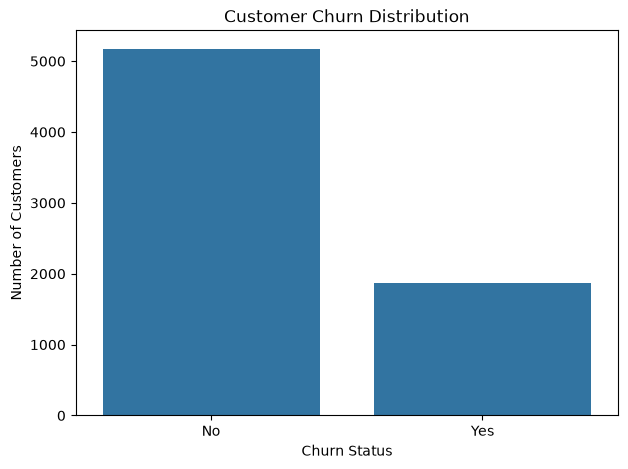

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

## 17. Identifying Numerical Features

Numerical features contain values that can be represented using integers or floating-point numbers.

We use `select_dtypes()` to identify numerical columns programmatically.

The identified numerical columns are:

- `SeniorCitizen`
- `tenure`
- `MonthlyCharges`
- `TotalCharges`

**Note:** Although `SeniorCitizen` is stored as an integer, it represents a binary categorical variable (0 and 1). Therefore, it will be treated differently from continuous numerical features during analysis.

In [25]:
df_clean.select_dtypes(include=["int64", "float64"]).columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

## 18. Distribution Analysis of Numerical Features

Histograms are used to understand the distribution of numerical variables.

They help identify:

- Concentration of observations.
- Spread and variability of values.
- Skewness in distributions.
- Potential unusual values.

We visualize the following features:

1. `tenure`
2. `MonthlyCharges`
3. `TotalCharges`

The `SeniorCitizen` variable is excluded from this visualization because it represents a binary category rather than a continuous numerical variable.

These visualizations help us understand customer characteristics before investigating their relationship with churn.

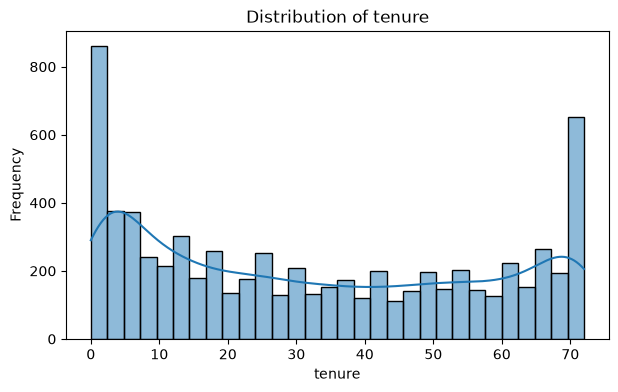

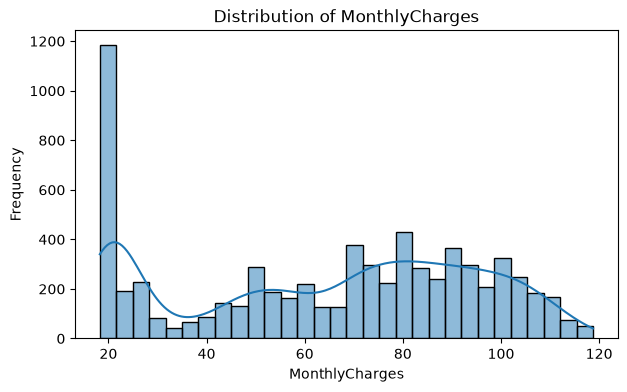

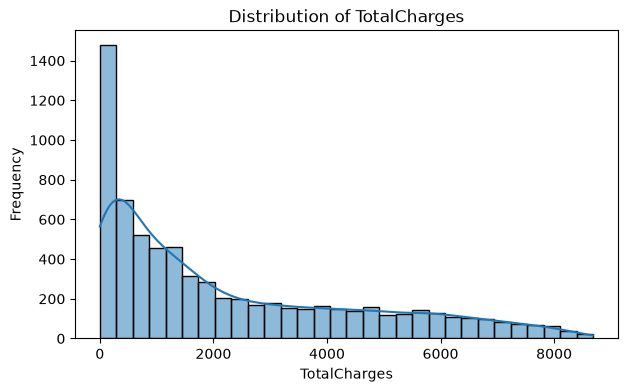

In [32]:
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]

for column in numerical_features:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(data=df_clean, x=column, bins=30, kde=True)
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.show()

### 18.1 Observations and Initial Insights

The distribution analysis of numerical features reveals the following observations:

**1. Tenure**
- Customers are distributed across different tenure periods.
- A noticeable concentration exists among customers with shorter tenure.
- Another concentration is observed among long-term customers.
- Further investigation is required to understand the relationship between tenure and customer churn.

**2. MonthlyCharges**
- Monthly charges show multiple concentrations across different price ranges.
- A significant number of customers have relatively low monthly charges.
- Many customers also fall within the higher monthly charge ranges.
- Different service subscriptions and combinations may contribute to these variations.

**3. TotalCharges**
- TotalCharges follows a positively skewed distribution.
- Most customers have relatively lower accumulated charges.
- A smaller proportion of customers have significantly higher accumulated charges.
- Customer tenure may influence the accumulated charges.

**Conclusion:**

The numerical features exhibit different distribution patterns and may provide useful information for understanding customer behaviour.

Further analysis will be performed to investigate their relationship with the target variable, `Churn`.

## 19. Categorical Feature Analysis

Categorical variables represent customer characteristics, subscription types and service preferences.

Unlike numerical variables, categorical variables represent distinct groups or categories.

Examples include gender, contract type, internet service and payment method.

Identifying categorical features allows us to understand the composition of the customer base and investigate how different customer groups behave.

We use Pandas `select_dtypes()` to identify columns containing string values.

In [35]:
categorical_features = df_clean.select_dtypes(include=["str"]).columns

categorical_features

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

## 20. Distribution of Categorical Features

After identifying the categorical columns, the next step is to examine the frequency of their unique categories.

This analysis helps us understand:

- The number of unique categories in each feature.
- The frequency of customers belonging to each category.
- The distribution of customer characteristics and subscribed services.

The `value_counts()` method is used to calculate the frequency of each category.

The customer identifier and target variable are excluded from this initial analysis because they serve different purposes.

In [36]:
categorical_features = df_clean.select_dtypes(include=["str"]).columns.drop(
    ["customerID", "Churn"]
)

for column in categorical_features:
    print(f"\nDistribution of {column}:")
    print(df_clean[column].value_counts())


Distribution of gender:
gender
Male      3555
Female    3488
Name: count, dtype: int64

Distribution of Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Distribution of Dependents:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Distribution of PhoneService:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Distribution of MultipleLines:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Distribution of InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Distribution of OnlineSecurity:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Distribution of OnlineBackup:
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

Distribution of DeviceProtection:
DeviceProtecti

In [37]:
categorical_summary = pd.concat(
    {
        column: df_clean[column].value_counts()
        for column in categorical_features
    },
    names=["Feature", "Category"]
).rename("Customer Count").reset_index()

categorical_summary

,Feature,Category,Customer Count
0,gender,Male,3555
1,gender,Female,3488
2,Partner,No,3641
3,Partner,Yes,3402
4,Dependents,No,4933
5,Dependents,Yes,2110
6,PhoneService,Yes,6361
7,PhoneService,No,682
8,MultipleLines,No,3390
9,MultipleLines,Yes,2971


### 20.1 Observations and Initial Business Insights

The categorical distribution analysis provides an overview of customer demographics, subscribed services, contract preferences and billing behaviour.

**1. Customer Demographics**
- Male and female customers are almost equally distributed.
- Customers without dependents represent the majority of the dataset.
- Customers with and without partners have relatively similar representation.

**2. Service Subscriptions**
- Most customers have subscribed to phone services.
- Fiber optic is the most common internet service.
- A considerable number of customers have not subscribed to additional services such as online security, online backup and technical support.

**3. Contract and Billing**
- Month-to-month contracts represent the largest contract category.
- Paperless billing is used by the majority of customers.
- Electronic check is the most frequently used payment method.

**4. Data Observations**
- Categories such as `No internet service` and `No phone service` represent service availability conditions rather than missing values.
- These categories will be retained during subsequent preprocessing.

**Initial Business Hypotheses**

The following relationships require further investigation:

- Whether month-to-month contracts are associated with higher churn.
- Whether customers without technical support have higher churn rates.
- Whether internet service type influences customer churn.
- Whether payment methods are associated with differences in customer retention.

These observations will guide the upcoming churn analysis.

## 21. Relationship Between Categorical Features and Churn

After understanding the distribution of individual categorical features, the next step is to investigate their relationship with the target variable, `Churn`.

This analysis helps identify customer groups that exhibit different churn behaviours.

We use cross-tabulation to compare categorical features against the target variable.

The analysis will help investigate whether customer characteristics, subscribed services, contract preferences and payment methods are associated with customer churn.

The findings can provide useful insights for developing targeted customer retention strategies.

In [38]:
pd.crosstab(df_clean["Contract"], df_clean["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


## 22. Calculating Contract-wise Churn Rates

The previous cross-tabulation provided the number of customers who churned and remained within each contract category.

However, customer counts alone are insufficient for comparing churn behaviour because the total number of customers differs across contract categories.

To make a fair comparison, we calculate the churn percentage within each contract category.

**Formula:**

Churn Rate = (Number of Churned Customers / Total Customers in the Category) × 100

This analysis helps identify which contract categories have a higher proportion of churned customers.

The results can help the telecom company understand the relationship between contract duration and customer retention.

In [39]:
contract_churn_percentage = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

contract_churn_percentage

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858



### 22.1 Observations and Business Insights

The contract-wise churn analysis reveals a significant difference in churn rates across contract categories.

| Contract Type | Churn Rate |
|---|---:|
| Month-to-month | 42.71% |
| One year | 11.27% |
| Two year | 2.83% |

**Key Findings:**

1. Month-to-month contracts have the highest churn rate at 42.71%.
2. One-year contracts have a considerably lower churn rate of 11.27%.
3. Two-year contracts have the lowest churn rate at 2.83%.

**Business Implications:**

- Customers with month-to-month contracts could be prioritized for retention initiatives.
- The company could investigate whether suitable long-term contract incentives improve customer retention.
- Customer retention strategies should consider contract preferences and other behavioural characteristics.

**Conclusion:**

Contract type appears to be strongly associated with customer churn in this dataset. Customers with month-to-month contracts exhibit substantially higher churn rates than customers with longer-term contracts.

## 23. Visualizing Contract-wise Churn Rates

A bar chart is used to compare churn percentages across different contract categories.

This visualization helps identify contract types associated with higher customer attrition.

We focus on the `Yes` category because it represents customers who have discontinued their services.

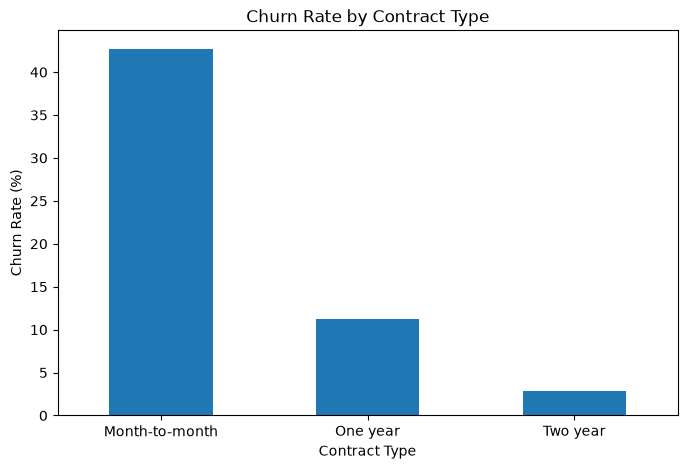

In [40]:
contract_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Key Findings – Contract Type vs Churn

- Month-to-month customers have the highest churn rate at approximately **42.71%**.
- One-year contract customers have a churn rate of approximately **11.27%**.
- Two-year contract customers have the lowest churn rate at approximately **2.83%**.
- Customers with longer-term contracts appear less likely to churn.
- The company could consider targeted retention offers to encourage month-to-month customers to choose longer-term contracts.

**Business Insight:** Contract type is an important feature to investigate when predicting customer churn. However, other customer characteristics may also influence churn.

In [41]:
pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"]
)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [42]:
payment_churn_percentage = pd.crosstab(
    df_clean["PaymentMethod"],
    df_clean["Churn"],
    normalize="index"
) * 100

payment_churn_percentage

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


### Key Findings – Payment Method vs Churn

- Electronic check customers have the highest churn rate at approximately **45.29%**.
- Credit card customers have the lowest churn rate at approximately **15.24%**.
- Bank transfer customers have a churn rate of approximately **16.71%**.
- Mailed check customers have a churn rate of approximately **19.11%**.
- Electronic check customers show a noticeably higher churn rate compared to other payment methods.

**Business Insight:** Payment method may be a useful feature for identifying customers at risk of churn. The company could investigate the reasons behind the higher churn rate among electronic-check customers and develop suitable retention strategies.

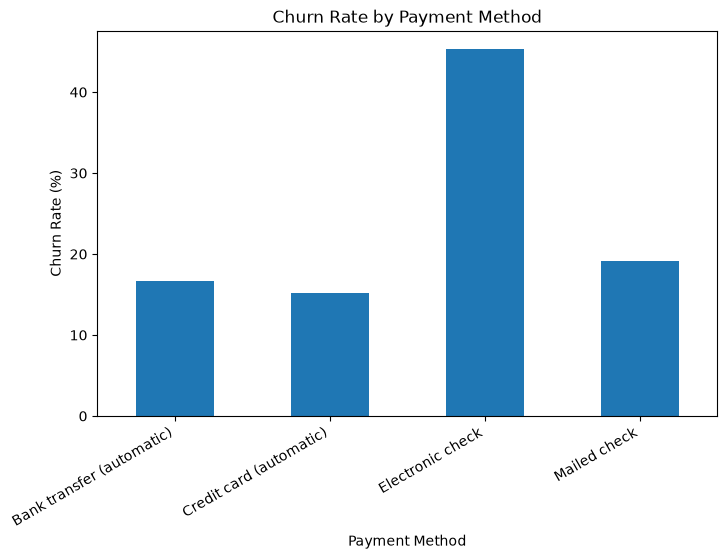

In [43]:
payment_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.show()

### Observations from Payment Method Churn Visualization

- Electronic check has the highest churn rate (45.29%).
- Credit card (automatic) has the lowest churn rate (15.24%).
- Customers using automatic payment methods show comparatively lower churn rates.
- Payment method may help identify customer groups that require additional retention attention.

**Business Insight:** The company should investigate the reasons behind the higher churn among electronic-check customers and explore ways to improve their payment experience.

In [44]:
pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"]
)

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [45]:
internet_churn_percentage = pd.crosstab(
    df_clean["InternetService"],
    df_clean["Churn"],
    normalize="index"
) * 100

internet_churn_percentage

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


### Key Findings – Internet Service vs Churn

- Fiber optic customers have the highest churn rate at approximately **41.89%**.
- DSL customers have a churn rate of approximately **18.96%**.
- Customers without internet service have the lowest churn rate at approximately **7.40%**.
- Fiber optic customers show a noticeably higher churn rate compared to other categories.

**Business Insight:** Internet service type may be an important feature for predicting customer churn. The company should investigate customer satisfaction, service quality, pricing and support to understand the higher churn rate among Fiber optic customers.

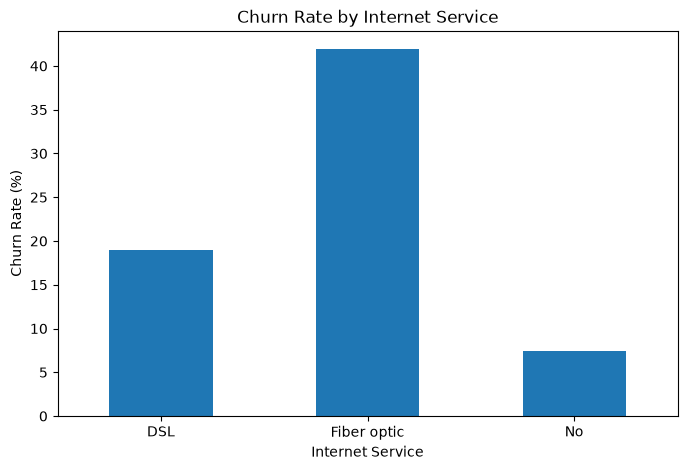

In [46]:
internet_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Internet Service Churn Visualization

- Fiber optic customers have the highest churn rate (41.89%).
- DSL customers have a churn rate of 18.96%.
- Customers without internet service have the lowest churn rate (7.40%).
- Internet service type appears to be an important factor to investigate when understanding customer churn.

**Business Insight:** The telecom company should investigate service quality, pricing and customer satisfaction among Fiber optic customers to understand their higher churn rate.

In [47]:
pd.crosstab(
    df_clean["OnlineSecurity"],
    df_clean["Churn"]
)

Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


In [48]:
security_churn_percentage = pd.crosstab(
    df_clean["OnlineSecurity"],
    df_clean["Churn"],
    normalize="index"
) * 100

security_churn_percentage

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


### Key Findings – Online Security vs Churn

- Customers without Online Security have the highest churn rate at approximately **41.77%**.
- Customers with Online Security have a churn rate of approximately **14.61%**.
- Customers without internet service have the lowest churn rate at approximately **7.40%**.
- Customers who subscribe to Online Security show a comparatively lower churn rate.

**Business Insight:** Online Security subscription may be a useful feature for predicting customer churn. The company could investigate customer needs and satisfaction with its security services and consider suitable service offers to improve retention.

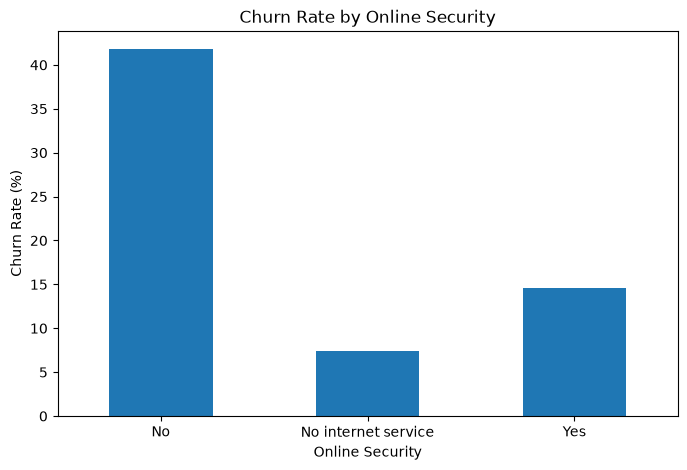

In [49]:
security_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Online Security Churn Visualization

- Customers without Online Security have the highest churn rate (41.77%).
- Customers with Online Security have a churn rate of 14.61%.
- Customers without internet service have the lowest churn rate (7.40%).
- Online Security subscription appears to be associated with differences in customer churn.

**Business Insight:** The telecom company could investigate whether security service availability, pricing or customer awareness influences customer retention.

In [50]:
pd.crosstab(
    df_clean["TechSupport"],
    df_clean["Churn"]
)

Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


In [51]:
techsupport_churn_percentage = pd.crosstab(
    df_clean["TechSupport"],
    df_clean["Churn"],
    normalize="index"
) * 100

techsupport_churn_percentage

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


### Key Findings – Tech Support vs Churn

- Customers without Tech Support have the highest churn rate at approximately **41.64%**.
- Customers with Tech Support have a churn rate of approximately **15.17%**.
- Customers without internet service have the lowest churn rate at approximately **7.40%**.
- Customers who subscribe to Tech Support show a comparatively lower churn rate.

**Business Insight:** Tech Support subscription may be a useful feature for predicting customer churn. The company could investigate customer support quality and technical service requirements to understand the higher churn rate among customers without Tech Support.

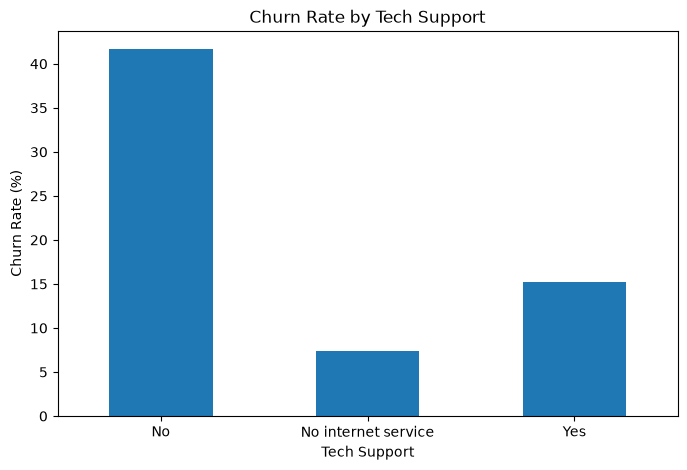

In [53]:
techsupport_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Tech Support Churn Visualization

- Customers without Tech Support have the highest churn rate (41.64%).
- Customers with Tech Support have a churn rate of 15.17%.
- Customers without internet service have the lowest churn rate (7.40%).
- Tech Support subscription appears to be associated with differences in customer churn.

**Business Insight:** The telecom company could investigate customer support quality, response times and technical service requirements to understand the higher churn rate among customers without Tech Support.

In [55]:
pd.crosstab(
    df_clean["OnlineBackup"],
    df_clean["Churn"]
)

Churn,No,Yes
OnlineBackup,,
No,1855,1233
No internet service,1413,113
Yes,1906,523


In [56]:
backup_churn_percentage = pd.crosstab(
    df_clean["OnlineBackup"],
    df_clean["Churn"],
    normalize="index"
) * 100

backup_churn_percentage

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


### Key Findings – Online Backup vs Churn

- Customers without Online Backup have the highest churn rate at approximately **39.93%**.
- Customers with Online Backup have a churn rate of approximately **21.53%**.
- Customers without internet service have the lowest churn rate at approximately **7.40%**.
- Customers who subscribe to Online Backup show a comparatively lower churn rate.

**Business Insight:** Online Backup subscription may be a useful feature for predicting customer churn. The company could investigate customer requirements, service awareness and pricing to understand the higher churn rate among customers without Online Backup.

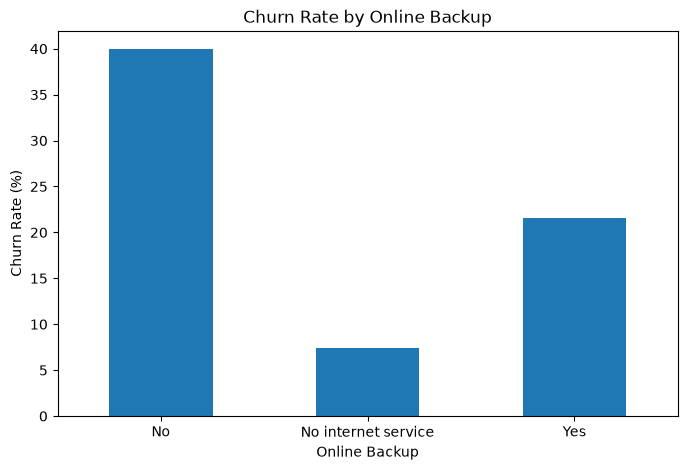

In [57]:
backup_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Online Backup")
plt.xlabel("Online Backup")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Online Backup Churn Visualization

- Customers without Online Backup have the highest churn rate (39.93%).
- Customers with Online Backup have a churn rate of 21.53%.
- Customers without internet service have the lowest churn rate (7.40%).
- Online Backup subscription appears to be associated with differences in customer churn.

**Business Insight:** The telecom company could investigate customer requirements, service awareness and pricing to understand the higher churn rate among customers without Online Backup.

In [58]:
pd.crosstab(
    df_clean["DeviceProtection"],
    df_clean["Churn"]
)

Churn,No,Yes
DeviceProtection,,
No,1884,1211
No internet service,1413,113
Yes,1877,545


In [59]:
device_churn_percentage = pd.crosstab(
    df_clean["DeviceProtection"],
    df_clean["Churn"],
    normalize="index"
) * 100

device_churn_percentage

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


### Key Findings – Device Protection vs Churn

- Customers without Device Protection have the highest churn rate at approximately **39.13%**.
- Customers with Device Protection have a churn rate of approximately **22.50%**.
- Customers without internet service have the lowest churn rate at approximately **7.40%**.
- Customers who subscribe to Device Protection show a comparatively lower churn rate.

**Business Insight:** Device Protection subscription may be a useful feature for predicting customer churn. The company could investigate customer requirements, service awareness and pricing to understand the higher churn rate among customers without Device Protection.

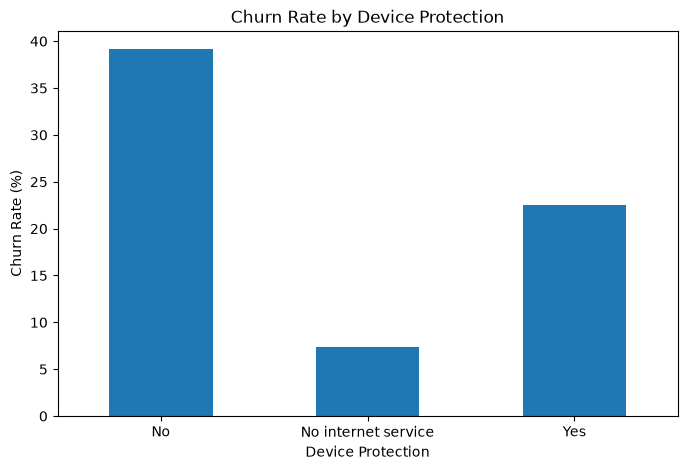

In [60]:
device_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Device Protection")
plt.xlabel("Device Protection")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Device Protection Churn Visualization

- Customers without Device Protection have the highest churn rate (39.13%).
- Customers with Device Protection have a churn rate of 22.50%.
- Customers without internet service have the lowest churn rate (7.40%).
- Device Protection subscription appears to be associated with differences in customer churn.

**Business Insight:** The telecom company could investigate customer requirements, service awareness and pricing to understand the higher churn rate among customers without Device Protection.

In [61]:
pd.crosstab(
    df_clean["StreamingTV"],
    df_clean["Churn"]
)

Churn,No,Yes
StreamingTV,,
No,1868,942
No internet service,1413,113
Yes,1893,814


In [62]:
streamingtv_churn_percentage = pd.crosstab(
    df_clean["StreamingTV"],
    df_clean["Churn"],
    normalize="index"
) * 100

streamingtv_churn_percentage

Churn,No,Yes
StreamingTV,,
No,66.476868,33.523132
No internet service,92.595020,7.404980
Yes,69.929812,30.070188


### Key Findings – Streaming TV vs Churn

- Customers without Streaming TV have a churn rate of approximately **33.52%**.
- Customers with Streaming TV have a churn rate of approximately **30.07%**.
- Customers without internet service have the lowest churn rate at approximately **7.40%**.
- The difference between customers with and without Streaming TV is relatively small.

**Business Insight:** Streaming TV subscription shows a smaller difference in churn rates compared to some other services analysed. Its usefulness for churn prediction should be evaluated alongside other customer features.

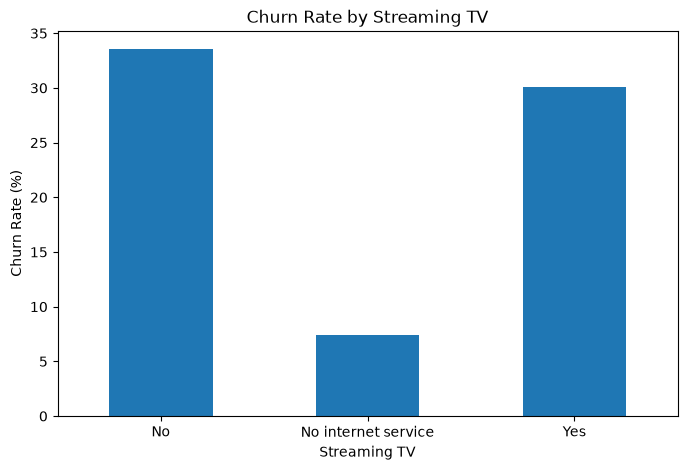

In [63]:
streamingtv_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Streaming TV")
plt.xlabel("Streaming TV")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Streaming TV Churn Visualization

- Customers without Streaming TV have a churn rate of 33.52%.
- Customers with Streaming TV have a churn rate of 30.07%.
- Customers without internet service have the lowest churn rate (7.40%).
- The difference between customers with and without Streaming TV is relatively small.

**Business Insight:** Streaming TV subscription shows a relatively small difference in churn rates. Its importance for predicting churn should be evaluated along with other customer features.

In [64]:
pd.crosstab(
    df_clean["StreamingMovies"],
    df_clean["Churn"]
)

Churn,No,Yes
StreamingMovies,,
No,1847,938
No internet service,1413,113
Yes,1914,818


In [65]:
streamingmovies_churn_percentage = pd.crosstab(
    df_clean["StreamingMovies"],
    df_clean["Churn"],
    normalize="index"
) * 100

streamingmovies_churn_percentage

Churn,No,Yes
StreamingMovies,,
No,66.319569,33.680431
No internet service,92.595020,7.404980
Yes,70.058565,29.941435


### Key Findings – Streaming Movies vs Churn

- Customers without Streaming Movies have a churn rate of approximately **33.68%**.
- Customers with Streaming Movies have a churn rate of approximately **29.94%**.
- Customers without internet service have the lowest churn rate at approximately **7.40%**.
- The difference between customers with and without Streaming Movies is relatively small.

**Business Insight:** Streaming Movies subscription shows a relatively small difference in churn rates. Its usefulness for predicting customer churn should be evaluated alongside other customer features.

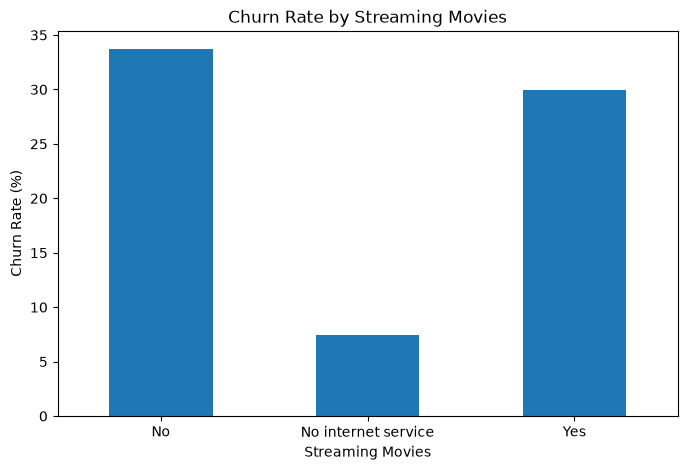

In [66]:
streamingmovies_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Streaming Movies")
plt.xlabel("Streaming Movies")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Streaming Movies Churn Visualization

- Customers without Streaming Movies have a churn rate of 33.68%.
- Customers with Streaming Movies have a churn rate of 29.94%.
- Customers without internet service have the lowest churn rate (7.40%).
- The difference between customers with and without Streaming Movies is relatively small.

**Business Insight:** Streaming Movies subscription shows a relatively small difference in churn rates. Its predictive importance should be evaluated alongside other customer features.

In [67]:
pd.crosstab(
    df_clean["MultipleLines"],
    df_clean["Churn"]
)

Churn,No,Yes
MultipleLines,,
No,2541,849
No phone service,512,170
Yes,2121,850


In [68]:
multiplelines_churn_percentage = pd.crosstab(
    df_clean["MultipleLines"],
    df_clean["Churn"],
    normalize="index"
) * 100

multiplelines_churn_percentage

Churn,No,Yes
MultipleLines,,
No,74.955752,25.044248
No phone service,75.073314,24.926686
Yes,71.390104,28.609896


### Key Findings – Multiple Lines vs Churn

- Customers with multiple phone lines have the highest churn rate at approximately **28.61%**.
- Customers without multiple lines have a churn rate of approximately **25.04%**.
- Customers without phone service have a churn rate of approximately **24.93%**.
- The differences in churn rates across the three categories are relatively small.

**Business Insight:** Multiple Lines shows a relatively small difference in churn rates. Its predictive importance should be evaluated alongside other customer features.

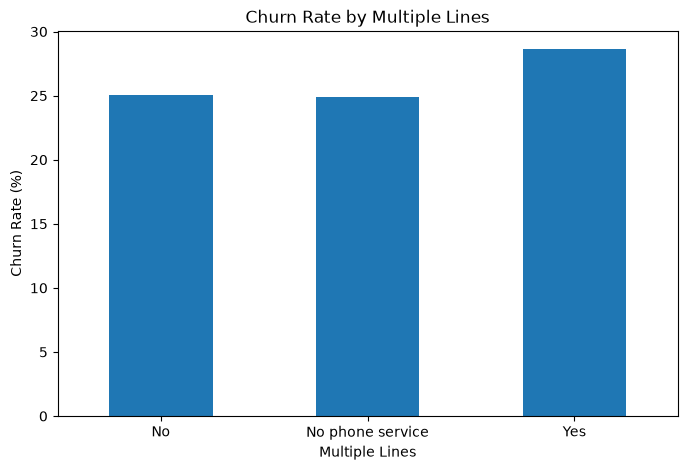

In [69]:
multiplelines_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Multiple Lines")
plt.xlabel("Multiple Lines")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Multiple Lines Churn Visualization

- Customers with multiple phone lines have the highest churn rate (28.61%).
- Customers without multiple phone lines have a churn rate of 25.04%.
- Customers without phone service have a churn rate of 24.93%.
- The differences in churn rates across the categories are relatively small.

**Business Insight:** Multiple Lines shows a relatively small difference in churn rates. Its predictive importance should be evaluated alongside other customer features.

In [70]:
pd.crosstab(
    df_clean["PaperlessBilling"],
    df_clean["Churn"]
)

Churn,No,Yes
PaperlessBilling,,
No,2403,469
Yes,2771,1400


In [71]:
paperless_churn_percentage = pd.crosstab(
    df_clean["PaperlessBilling"],
    df_clean["Churn"],
    normalize="index"
) * 100

paperless_churn_percentage

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


### Key Findings – Paperless Billing vs Churn

- Customers using Paperless Billing have a churn rate of approximately **33.57%**.
- Customers not using Paperless Billing have a churn rate of approximately **16.33%**.
- Paperless Billing customers show a noticeably higher churn rate.
- The difference between the two categories is approximately 17.24 percentage points.

**Business Insight:** Paperless Billing may be a useful feature for predicting customer churn. The company could investigate billing experiences and customer payment preferences to understand this difference.

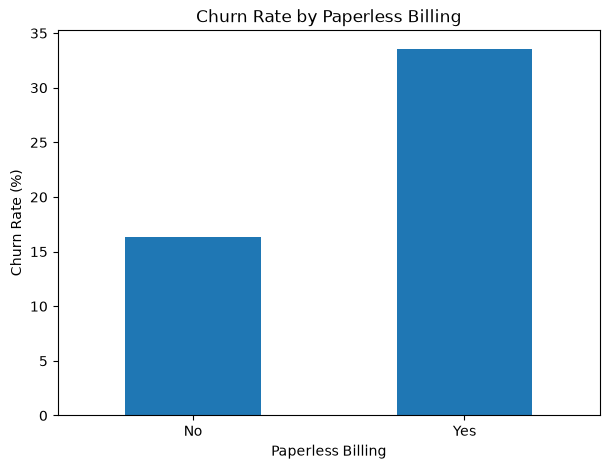

In [72]:
paperless_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Paperless Billing Churn Visualization

- Customers using Paperless Billing have a churn rate of 33.57%.
- Customers not using Paperless Billing have a churn rate of 16.33%.
- Paperless Billing customers show a noticeably higher churn rate.
- The difference between the two categories is approximately 17.24 percentage points.

**Business Insight:** The company should investigate billing experiences and payment preferences among Paperless Billing customers to understand their higher churn rate.

In [73]:
pd.crosstab(
    df_clean["gender"],
    df_clean["Churn"]
)

Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


In [74]:
gender_churn_percentage = pd.crosstab(
    df_clean["gender"],
    df_clean["Churn"],
    normalize="index"
) * 100

gender_churn_percentage

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


### Key Findings – Gender vs Churn

- Female customers have a churn rate of approximately **26.92%**.
- Male customers have a churn rate of approximately **26.16%**.
- The difference between the two categories is approximately 0.76 percentage points.
- Both categories have very similar churn rates.

**Business Insight:** Gender does not show a substantial difference in churn rates in this dataset. Its predictive importance should be evaluated alongside other customer features.

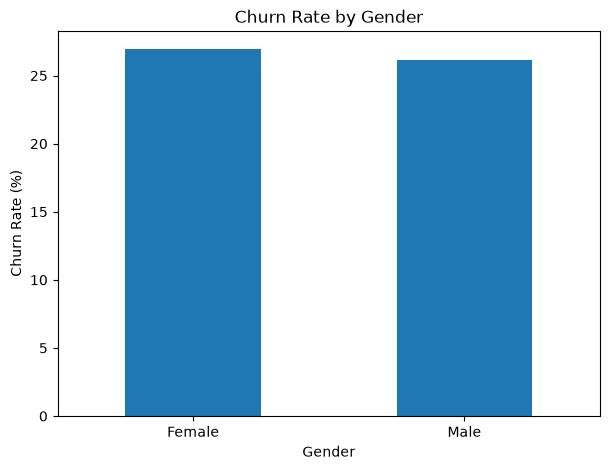

In [76]:
gender_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Gender Churn Visualization

- Female customers have a churn rate of 26.92%.
- Male customers have a churn rate of 26.16%.
- The difference between the two categories is approximately 0.76 percentage points.
- Both categories show very similar churn rates.

**Business Insight:** Gender shows a relatively small difference in churn rates and may have limited predictive value compared with other features.

In [77]:
pd.crosstab(
    df_clean["SeniorCitizen"],
    df_clean["Churn"]
)

Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


In [78]:
senior_churn_percentage = pd.crosstab(
    df_clean["SeniorCitizen"],
    df_clean["Churn"],
    normalize="index"
) * 100

senior_churn_percentage

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


### Key Findings – Senior Citizen vs Churn

- Senior citizens have a churn rate of approximately **41.68%**.
- Non-senior customers have a churn rate of approximately **23.61%**.
- Senior citizens show a noticeably higher churn rate.
- The difference between the two categories is approximately 18.08 percentage points.

**Business Insight:** Senior Citizen status may be a useful feature for predicting customer churn. The company could investigate service accessibility, pricing and customer support requirements among senior customers.

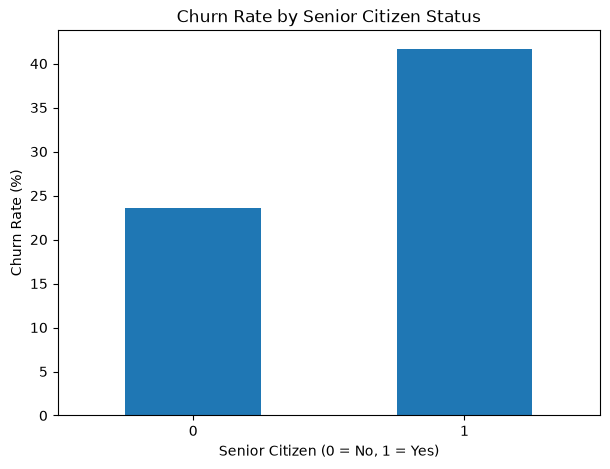

In [79]:
senior_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Senior Citizen Churn Visualization

- Non-senior customers have a churn rate of 23.61%.
- Senior citizens have a churn rate of 41.68%.
- Senior citizens show a noticeably higher churn rate.
- The difference between the two categories is approximately 18.08 percentage points.

**Business Insight:** The company could investigate service accessibility, pricing and customer support requirements among senior customers to understand their higher churn rate.

In [80]:
pd.crosstab(
    df_clean["Partner"],
    df_clean["Churn"]
)

Churn,No,Yes
Partner,,
No,2441,1200
Yes,2733,669


In [81]:
partner_churn_percentage = pd.crosstab(
    df_clean["Partner"],
    df_clean["Churn"],
    normalize="index"
) * 100

partner_churn_percentage

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


### Key Findings – Partner vs Churn

- Customers without a partner have a churn rate of approximately **32.96%**.
- Customers with a partner have a churn rate of approximately **19.66%**.
- Customers without a partner show a noticeably higher churn rate.
- The difference between the two categories is approximately 13.29 percentage points.

**Business Insight:** Partner status may be a useful feature for predicting customer churn. The company could investigate differences in customer requirements and engagement patterns between these groups.

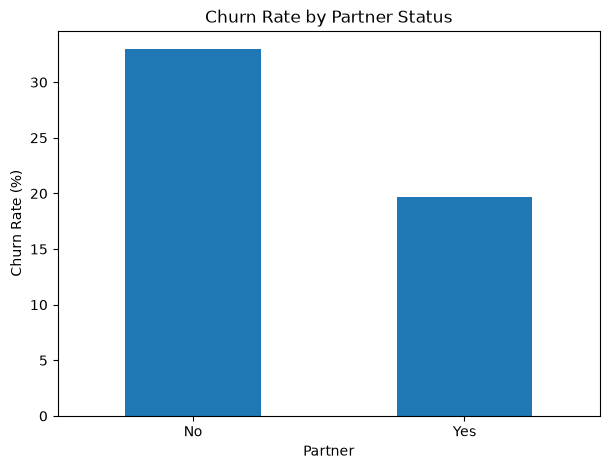

In [82]:
partner_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Partner Churn Visualization

- Customers without a partner have a churn rate of 32.96%.
- Customers with a partner have a churn rate of 19.66%.
- Customers without a partner show a noticeably higher churn rate.
- The difference between the two categories is approximately 13.29 percentage points.

**Business Insight:** The company could investigate differences in customer requirements and engagement patterns between customers with and without partners.

In [83]:
pd.crosstab(
    df_clean["Dependents"],
    df_clean["Churn"]
)

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326


In [84]:
dependents_churn_percentage = pd.crosstab(
    df_clean["Dependents"],
    df_clean["Churn"],
    normalize="index"
) * 100

dependents_churn_percentage

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


### Key Findings – Dependents vs Churn

- Customers without dependents have a churn rate of approximately **31.28%**.
- Customers with dependents have a churn rate of approximately **15.45%**.
- Customers without dependents show a noticeably higher churn rate.
- The difference between the two categories is approximately 15.83 percentage points.

**Business Insight:** Dependents status may be a useful feature for predicting customer churn. The company could investigate differences in household requirements and subscription preferences between these customer groups.

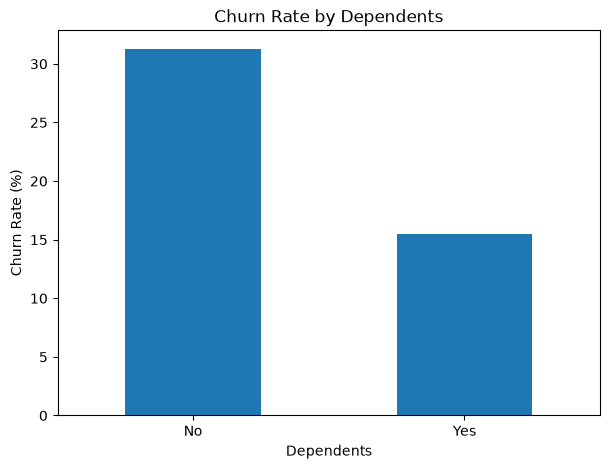

In [85]:
dependents_churn_percentage["Yes"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Churn Rate by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

### Observations from Dependents Churn Visualization

- Customers without dependents have a churn rate of 31.28%.
- Customers with dependents have a churn rate of 15.45%.
- Customers without dependents show a noticeably higher churn rate.
- The difference between the two categories is approximately 15.83 percentage points.

**Business Insight:** The company could investigate differences in household requirements and subscription preferences between customers with and without dependents.

In [86]:
df_clean.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

### Key Findings – Customer Tenure vs Churn

- Customers who stayed have an average tenure of approximately **37.57 months**.
- Customers who churned have an average tenure of approximately **17.98 months**.
- Customers who churned had approximately 19.59 fewer months of tenure on average.
- Customer tenure appears to have a noticeable relationship with churn.

**Business Insight:** New customers may require additional attention during their initial months. The company could introduce onboarding support, early engagement programs and targeted retention offers to improve customer retention.

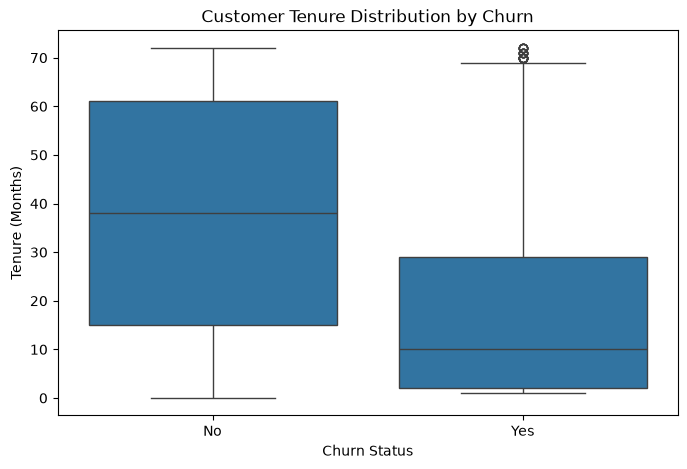

In [87]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

### Observations from Customer Tenure Distribution by Churn

- Customers who stayed have a median tenure of approximately 38 months.
- Customers who churned have a median tenure of approximately 10 months.
- Customers who churned generally have shorter tenure than customers who stayed.
- The tenure distribution indicates that many customers leave during their initial months.
- A few long-tenure customers also eventually churned.

**Business Insight:** Customer tenure appears to be an important indicator of churn risk. The company should focus on early customer engagement, onboarding support and retention strategies to reduce churn among new customers.

In [88]:
df_clean.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

### Key Findings – Monthly Charges vs Churn

- Customers who stayed have average monthly charges of approximately **$61.27**.
- Customers who churned have average monthly charges of approximately **$74.44**.
- Customers who churned pay approximately $13.18 more per month on average.
- Higher monthly charges appear to be associated with customer churn.

**Business Insight:** Monthly Charges may be an important feature for predicting customer churn. The company could investigate pricing structures, service packages and perceived value among customers with higher monthly bills.

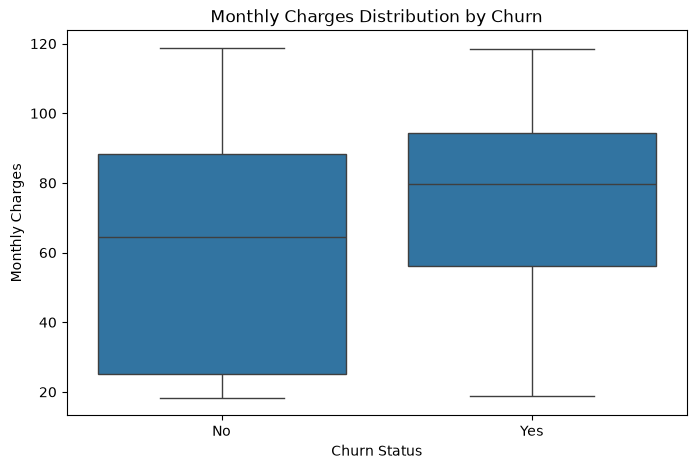

In [89]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.show()

### Observations from Monthly Charges Distribution by Churn

- Customers who stayed have a median monthly charge of approximately $64.
- Customers who churned have a median monthly charge of approximately $80.
- Customers who churned generally have higher monthly charges.
- The distribution suggests an association between higher monthly charges and customer churn.

**Business Insight:** Monthly Charges may be an important feature for predicting churn. The company should investigate pricing structures, service packages and perceived value among customers with higher monthly bills.

In [90]:
df_clean.groupby("Churn")["TotalCharges"].mean()

Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64

### Key Findings – Total Charges vs Churn

- Customers who stayed have average total charges of approximately **$2,549.91**.
- Customers who churned have average total charges of approximately **$1,531.80**.
- Customers who stayed have accumulated higher total charges.
- This difference may be related to the longer average tenure of customers who stayed.

**Business Insight:** TotalCharges may be a useful feature for predicting customer churn. However, it should be analysed alongside Tenure because customers who remain with the company longer naturally accumulate higher total charges.

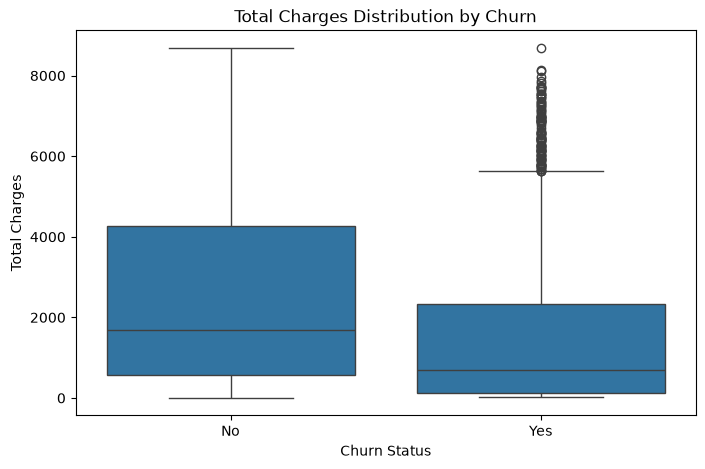

In [91]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges Distribution by Churn")
plt.xlabel("Churn Status")
plt.ylabel("Total Charges")
plt.show()

### Observations from Total Charges Distribution by Churn

- Customers who stayed have a higher median TotalCharges than customers who churned.
- Customers who stayed generally accumulated higher total charges.
- Customers who churned show a lower median TotalCharges.
- Several high-value outliers are visible among customers who churned.
- TotalCharges may be related to customer tenure because longer-serving customers generally accumulate higher charges.

**Business Insight:** TotalCharges may help identify customer churn patterns. However, it should be analysed alongside Tenure because both features are related to the duration of customer service.

In [92]:
numerical_df = df_clean.select_dtypes(
    include=["int64", "float64"]
)

numerical_df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65


In [93]:
correlation_matrix = numerical_df.corr()

correlation_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.103006
tenure,0.016567,1.000000,0.247900,0.826178
MonthlyCharges,0.220173,0.247900,1.000000,0.651174
TotalCharges,0.103006,0.826178,0.651174,1.000000


### Key Findings – Numerical Feature Correlation

- Tenure and TotalCharges have a strong positive correlation of approximately **0.826**.
- MonthlyCharges and TotalCharges have a positive correlation of approximately **0.651**.
- Tenure and MonthlyCharges have a weak positive correlation of approximately **0.248**.
- SeniorCitizen has relatively weak correlations with the other numerical features.

**Important Observation:** Tenure and TotalCharges are strongly related. Customers who stay longer generally accumulate higher total charges.

**Conclusion:** Correlation analysis helps identify relationships and potential overlap between numerical features. These relationships should be considered during feature selection and model development.

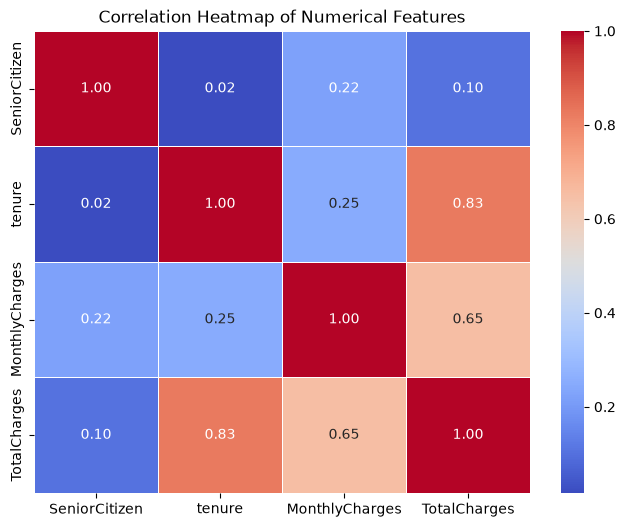

In [94]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### Observations from Correlation Heatmap

- Tenure and TotalCharges show a strong positive correlation (0.83).
- MonthlyCharges and TotalCharges show a moderately strong positive correlation (0.65).
- Tenure and MonthlyCharges show a weak positive correlation (0.25).
- SeniorCitizen has relatively weak correlations with the other numerical features.
- The diagonal values are 1.00 because every feature is perfectly correlated with itself.

**Conclusion:** Tenure and TotalCharges have a strong relationship. This is expected because customers who remain subscribed for longer periods generally accumulate higher total charges.

Correlation analysis helps identify relationships between numerical features and provides useful information for the upcoming feature preparation and model-building stages.

# Overall Exploratory Data Analysis (EDA) Summary

Exploratory Data Analysis was performed on the IBM Telco Customer Churn dataset to understand customer characteristics, service subscriptions and factors associated with customer churn.

### 1. Dataset Overview
- Total customer records: 7,043
- Total columns: 21
- Target variable: Churn
- Churned customers: 1,869 (26.54%)
- Retained customers: 5,174 (73.46%)

### 2. Important Categorical Feature Observations

- **Contract:** Month-to-month customers have a considerably higher churn rate (42.71%) than one-year (11.27%) and two-year (2.83%) contract customers.
- **Payment Method:** Customers using electronic checks have a higher churn rate (45.29%) than customers using other payment methods.
- **Internet Service:** Fiber optic customers have a churn rate of 41.89%.
- **Online Security:** Customers without Online Security have a churn rate of 41.77%.
- **Tech Support:** Customers without Tech Support have a churn rate of 41.64%.
- **Paperless Billing:** Customers using Paperless Billing have a churn rate of 33.57%.
- **Senior Citizens:** Senior customers have a churn rate of 41.68%.
- **Partner and Dependents:** Customers without partners or dependents show higher churn rates.
- **Gender, Streaming TV, Streaming Movies and Multiple Lines:** These features show relatively smaller differences in churn rates.

### 3. Important Numerical Feature Observations

- Customers who churned have a lower average tenure (17.98 months) than customers who stayed (37.57 months).
- Customers who churned have higher average MonthlyCharges ($74.44) than customers who stayed ($61.27).
- Customers who stayed have higher average TotalCharges ($2,549.91) than customers who churned ($1,531.80).

### 4. Correlation Analysis

- Tenure and TotalCharges have a strong positive correlation (0.83).
- MonthlyCharges and TotalCharges have a positive correlation (0.65).
- Other numerical feature relationships are relatively weak.

### 5. Overall Business Insights

The analysis indicates that customer churn is associated with several factors, including contract type, payment method, service subscriptions, customer tenure and monthly charges.

The company could investigate targeted retention strategies such as:
- Encouraging long-term contracts.
- Improving customer support services.
- Reviewing pricing and service packages.
- Monitoring new customers during their initial months.
- Identifying customers who may be at higher risk of leaving.

### Conclusion

The EDA stage helped identify customer characteristics and patterns associated with churn. These findings will guide data preprocessing, feature preparation and machine learning model development.

In [95]:
df_clean.to_csv(
    "../data/processed/cleaned_telco_data.csv",
    index=False
)